# **Setup**

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import copy

from torch.utils.data import DataLoader, Subset

torch.manual_seed(0)
np.random.seed(0)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# CIFAR 10 transformation
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True, download=True, transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False, download=True, transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True,
                         num_workers=2, pin_memory=torch.cuda.is_available())

test_loader = DataLoader(test_dataset, batch_size=128, shuffle=True,
                        num_workers=2, pin_memory=torch.cuda.is_available())

class_names = train_dataset.classes

print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))
print("Classes:", class_names)

DAY51_CNN = 0.7304

Device: cpu
Training Images: 50000
Testing Images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [2]:
# Common training and evaluation functions
def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = F.cross_entropy(outputs, labels)
            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = correct / total
    average_loss = total_loss / total

    return accuracy, average_loss


def train_model(model, epochs=10, lr=0.01, seed=0):
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = model.to(device)

    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)

    history = {
        "train_acc": [],
        "val_acc": [],
        "train_loss": [],
        "val_loss": []
    }

    start_time = time.time()

    for epoch in range(epochs):
        model.train()

        correct = 0
        total = 0
        total_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = F.cross_entropy(outputs, labels)

            loss.backward()

            optimizer.step()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

            total_loss += loss.item() * labels.size(0)

        train_acc = correct / total
        train_loss = total_loss / total

        val_acc, val_loss = evaluate_model(model, test_loader)

        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(f"Epoch {epoch+1}/{epochs} | "
             f"Train Acc: {train_acc:.4f} | "
             f"Test Acc: {val_acc:.4f}")


    training_time = time.time() - start_time

    return model, history, training_time


def count_parameters(model):
    return sum(p.numel()
              for p in model.parameters()
              if p.requires_grad)

# **Part A — The residual block itself**
## **TASK 01 — Prove the block can do nothing**

In [3]:
class ResidualBlock(nn.Module):
    def __init__(self, channels=16):
        super().__init__()
        self.conv1 = nn.Conv2d(
            channels, channels, 3, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(channels)

        self.conv2 = nn.Conv2d(
            channels, channels, 3, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(channels)


    def forward(self, x):
        identity = x
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity

        return F.relu(out)


class PlainBlock(nn.Module):
    def __init__(self, channels=16):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)

        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))

        return F.relu(x)



# Create models 
residual = ResidualBlock().to(device)
plain = PlainBlock().to(device)

# set all convolution weights to zero
for model in [residual, plain]:
    for layer in model.modules():
        if isinstance(layer, nn.Conv2d):
            nn.init.zeros_(layer.weight)


# Zero second batch normalization scale and shift
for model in [residual, plain]:
    nn.init.zeros_(model.bn2.weight)
    nn.init.zeros_(model.bn2.bias)


# Positive random input
x = torch.rand(4, 16, 32, 32).to(device)

residual.eval()
plain.eval()

with torch.no_grad():
    residual_output = residual(x)
    plain_output = plain(x)

    residual_difference = (residual_output - x).abs().max().item()
    plain_difference = (plain_output - x).abs().max().item()


print("Residual Difference:", residual_difference)
print("Plain Difference:", plain_difference)

Residual Difference: 0.0
Plain Difference: 0.9999853372573853


## **TASK 02 — When the shapes stop matching**

In [4]:
# Method 1 – 1×1 Projection Convolution
class ProjectionBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(16, 32, 3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 32, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(32)

        self.shortcut = nn.Conv2d(16, 32, 1, stride=2, bias=False)


    def forward(self, x):
        identity = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        return F.relu(out + identity)


x = torch.randn(4, 16, 32, 32).to(device)
block = ProjectionBlock().to(device)
output = block(x)

print("Input Shape:", x.shape)
print("Output Shape:", output.shape)

projection_params = count_parameters(block.shortcut)
total_params = count_parameters(block)

print("Projection Parameters:", projection_params)
print("Total Block Parameters:", total_params)

print("Projection Percentages:", projection_params / total_params * 100)

Input Shape: torch.Size([4, 16, 32, 32])
Output Shape: torch.Size([4, 32, 16, 16])
Projection Parameters: 512
Total Block Parameters: 14464
Projection Percentages: 3.5398230088495577


In [5]:
# Method 2 – Zero Padding and Subsampling
class PaddingBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(16, 32, 3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 32, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(32)


    def forward(self, x):
        identity = x[:, :, ::2, ::2]
        identity = F.pad(identity, (0, 0, 0, 0, 0, 16))
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        return F.relu(out + identity)



padding_block = PaddingBlock().to(device)
output = padding_block(x)

print("Padding Output Shape:", output.shape)
print("Shortcut Parameters:", sum(p.numel() for p in padding_block.parameters()))

Padding Output Shape: torch.Size([4, 32, 16, 16])
Shortcut Parameters: 13952


In [6]:
# Compare both methods
print("Projection Block Parameters:", count_parameters(block))
print("Padding Block Parameters:", count_parameters(padding_block))

Projection Block Parameters: 14464
Padding Block Parameters: 13952


In [7]:
# Training Comparison
projection_model = ProjectionBlock()
padding_model = PaddingBlock()

# CIFAR 10 images have 3 input channels, so these blocks need a 16 channels
# feature extractor before them.

class ShapeTestModel(nn.Module):
    def __init__(self, block):
        super(). __init__()
        self.stem = nn.Conv2d(3, 16, 3, padding=1)
        self.block = block
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(32, 10)

    def forward(self, x):
        x = F.relu(self.stem(x))
        x = self.block(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)

        return self.fc(x)


projection_model, projection_history, _ = train_model(
    ShapeTestModel(ProjectionBlock()), epochs=5, seed=0 
)

padding_model, padding_history, _ = train_model(
    ShapeTestModel(PaddingBlock()), epochs=5, seed=0
)

print("Projection Accuracy:", evaluate_model(projection_model, test_loader)[0])
print("Padding Accuracy:", evaluate_model(padding_model, test_loader)[0])

Epoch 1/5 | Train Acc: 0.3102 | Test Acc: 0.2329
Epoch 2/5 | Train Acc: 0.4352 | Test Acc: 0.2467
Epoch 3/5 | Train Acc: 0.4908 | Test Acc: 0.2808
Epoch 4/5 | Train Acc: 0.5222 | Test Acc: 0.3706
Epoch 5/5 | Train Acc: 0.5416 | Test Acc: 0.4640
Epoch 1/5 | Train Acc: 0.3127 | Test Acc: 0.2786
Epoch 2/5 | Train Acc: 0.4181 | Test Acc: 0.3879
Epoch 3/5 | Train Acc: 0.4814 | Test Acc: 0.4332
Epoch 4/5 | Train Acc: 0.5160 | Test Acc: 0.4718
Epoch 5/5 | Train Acc: 0.5426 | Test Acc: 0.4666
Projection Accuracy: 0.464
Padding Accuracy: 0.4666


**Explanation :-**
- In the projection method, the 1×1 convolution matches both the channel and spatial dimensions.
- In the padding method, zero values ​​are added to increase the number of channels.
- The projection method can learn, whereas padding does not learn anything.
- A stride of 2 is necessary for the 1×1 convolution; otherwise, the spatial size of the shortcut would remain 32×32, while the spatial size of the main path would become 16×16.

## **TASK 03 — The parameter accounting**

In [8]:
class PlainNetwork(nn.Module):
    def __init__(self, depth=8, width=32):
        super().__init__()
        layers = []
        in_channels = 3

        for i in range(depth):
            layers.append(nn.Conv2d(
                in_channels, width, kernel_size=3, padding=1, bias=False
            ))

            layers.append(nn.BatchNorm2d(width))
            layers.append(nn.ReLU(inplace=True))

            in_channels = width

        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(width, 10)


    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)



class ResidualNetwork(nn.Module):
    def __init__(self, depth=8, width=32):
        super().__init__()

        assert depth % 2 == 0

        self.stem = nn.Sequential(
            nn.Conv2d(3, width, 3, padding=1, bias=False),
            nn.BatchNorm2d(width),
            nn.ReLU(inplace=True)
        )

        self.blocks = nn.ModuleList([
            ResidualBlock(width)
            for _ in range(depth // 2)
        ])

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(width, 10)


    def forward(self, x):
        x = self.stem(x)

        for block in self.blocks:
            x = block(x)

        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)



# Compare same number of convolution layers
plain_model = PlainNetwork(depth=8, width=32)
res_model = ResidualNetwork(depth=8, width=32)

plain_params = count_parameters(plain_model)
res_params = count_parameters(res_model)

print("Plain Parameters:", plain_params)
print("Residual Parameters", res_params)
print("Difference:", abs(plain_params - res_params))

Plain Parameters: 66218
Residual Parameters 75498
Difference: 9280


In [9]:
# Both architectures have 8 convolutions:
# 1 stem + 7 remaining plain convolutions is not pairable.
# Use 8 plain convolutions versus 1 stem + 7 residual convolutions
# only if you match the architecture deliberately.


# Exact mathematical accounting:
width = 32
kernel_size = 3
depth = 8

conv_params = (depth * width * width * kernel_size * kernel_size)

print("Convolution Parameters:", conv_params)
print("Identity skip parameters: 0")
print("Additional skip parameters: 0")

Convolution Parameters: 73728
Identity skip parameters: 0
Additional skip parameters: 0


**Explanation :-**
- A skip connection is simply an addition operation. It contains no trainable weights.
  - Plain network: convolution weights.
  - Residual network: same convolution weights + shortcut addition.
  - Identity shortcut: zero additional parameters.
- A deep plain network can represent the same functions as a ResNet of the same size because it can learn identity mappings in its extra layers. However, finding those weights through gradient descent is difficult. ResNet makes optimization easier by providing a direct shortcut for information and gradients.

# **Part B — Reproduce the degradation problem**
## **TASK 04 — Make a deeper network perform worse**

In [10]:
depths = [8, 14, 20]

plain_results = {}
plain_histories = {}
plain_models = {}

for depth in depths:
    print("\nTraining Depth:", depth)

    model = PlainNetwork(depth=depth, width=32)

    model, history, training_time = train_model(
        model, epochs=10, lr=0.01, seed=0
    )

    plain_models[depth] = model
    plain_histories[depth] = history

    train_accuracy = history["train_acc"][-1]
    test_accuracy = evaluate_model(model, test_loader)[0]


    plain_results[depth] = {
        "depth": depth,
        "parameters": count_parameters(model),
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
        "time": training_time
    }



plain_table = pd.DataFrame(plain_results.values())

print(plain_table)


Training Depth: 8
Epoch 1/10 | Train Acc: 0.3798 | Test Acc: 0.4221
Epoch 2/10 | Train Acc: 0.5369 | Test Acc: 0.4439
Epoch 3/10 | Train Acc: 0.6136 | Test Acc: 0.5470
Epoch 4/10 | Train Acc: 0.6579 | Test Acc: 0.4641
Epoch 5/10 | Train Acc: 0.6861 | Test Acc: 0.6541
Epoch 6/10 | Train Acc: 0.7081 | Test Acc: 0.5775
Epoch 7/10 | Train Acc: 0.7256 | Test Acc: 0.6211
Epoch 8/10 | Train Acc: 0.7360 | Test Acc: 0.5779
Epoch 9/10 | Train Acc: 0.7496 | Test Acc: 0.6896
Epoch 10/10 | Train Acc: 0.7645 | Test Acc: 0.6852

Training Depth: 14
Epoch 1/10 | Train Acc: 0.3933 | Test Acc: 0.4530
Epoch 2/10 | Train Acc: 0.5742 | Test Acc: 0.5720
Epoch 3/10 | Train Acc: 0.6448 | Test Acc: 0.6109
Epoch 4/10 | Train Acc: 0.6865 | Test Acc: 0.4970
Epoch 5/10 | Train Acc: 0.7136 | Test Acc: 0.5058
Epoch 6/10 | Train Acc: 0.7334 | Test Acc: 0.6580
Epoch 7/10 | Train Acc: 0.7558 | Test Acc: 0.6209
Epoch 8/10 | Train Acc: 0.7701 | Test Acc: 0.6925
Epoch 9/10 | Train Acc: 0.7883 | Test Acc: 0.6950
Epoch 10/1

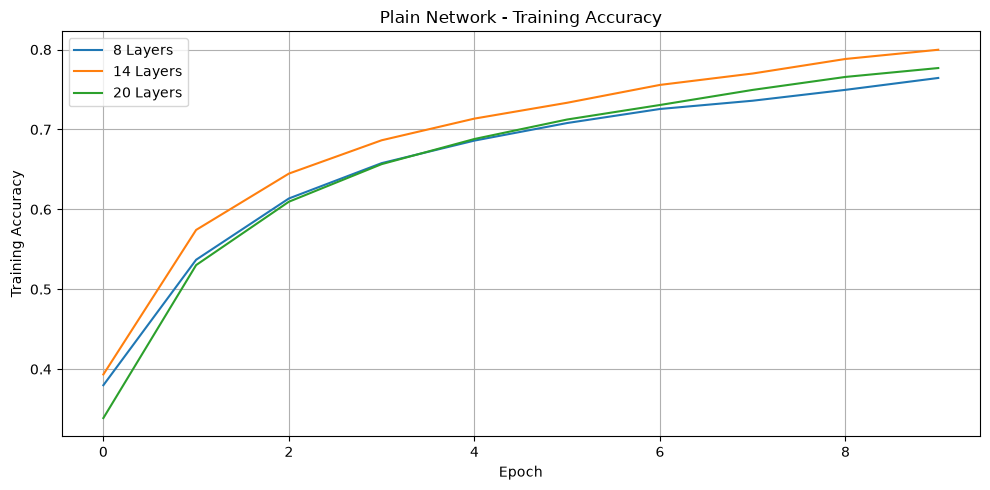

In [12]:
# Plot training accuracy:
fig, ax = plt.subplots(figsize=(10, 5))

for depth, history in plain_histories.items():
    ax.plot(
        history["train_acc"],
        label=f"{depth} Layers"
    )

ax.set(xlabel="Epoch", ylabel="Training Accuracy", title="Plain Network - Training Accuracy")
ax.legend()
ax.grid(0.3)

plt.tight_layout()
plt.show()

In [13]:
# Test Different Seeds
seed_results = []

for seed in [0, 1, 2]:
    print("Testing Seed:", seed)

    model = PlainNetwork(depth=20, width=32)

    model, history, _ = train_model(model, epochs=10, lr=0.01, seed=seed)

    accuracy = history["train_acc"][-1]

    seed_results.append({
        "seed": seed,
        "training_accuracy": accuracy
    })


print(pd.DataFrame(seed_results))

Testing Seed: 0
Epoch 1/10 | Train Acc: 0.3387 | Test Acc: 0.3685
Epoch 2/10 | Train Acc: 0.5302 | Test Acc: 0.5570
Epoch 3/10 | Train Acc: 0.6095 | Test Acc: 0.5599
Epoch 4/10 | Train Acc: 0.6566 | Test Acc: 0.4515
Epoch 5/10 | Train Acc: 0.6881 | Test Acc: 0.6062
Epoch 6/10 | Train Acc: 0.7125 | Test Acc: 0.5450
Epoch 7/10 | Train Acc: 0.7306 | Test Acc: 0.6235
Epoch 8/10 | Train Acc: 0.7495 | Test Acc: 0.7226
Epoch 9/10 | Train Acc: 0.7658 | Test Acc: 0.6944
Epoch 10/10 | Train Acc: 0.7769 | Test Acc: 0.7008
Testing Seed: 1
Epoch 1/10 | Train Acc: 0.3259 | Test Acc: 0.3449
Epoch 2/10 | Train Acc: 0.5185 | Test Acc: 0.4880
Epoch 3/10 | Train Acc: 0.6078 | Test Acc: 0.5365
Epoch 4/10 | Train Acc: 0.6606 | Test Acc: 0.6065
Epoch 5/10 | Train Acc: 0.6905 | Test Acc: 0.6326
Epoch 6/10 | Train Acc: 0.7110 | Test Acc: 0.6461
Epoch 7/10 | Train Acc: 0.7316 | Test Acc: 0.6494
Epoch 8/10 | Train Acc: 0.7503 | Test Acc: 0.6978
Epoch 9/10 | Train Acc: 0.7664 | Test Acc: 0.7151
Epoch 10/10 | Tra

**Explanation :-**
- If the training accuracy of a 20-layer network is lower than that of an 8-layer network, then degradation has occurred.
- If the test accuracy is low but the training accuracy is high, then that is overfitting.
- Training accuracy decreases due to overfitting explanation rule out because overfitting generally means the model fits training data better but generalizes poorly.
- A deeper network can theoretically imitate a shallow network using identity mappings, so the problem is optimization, not representational capacity.
- Common reasons include vanishing gradients, poor initialization and optimization difficulty. These can contribute, but they do not fully explain why a deeper model with greater representational capacity performs worse on training data.

## **TASK 05 — Add the skips and nothing else**

In [14]:
residual_results = {}
residual_histories = {}
residual_models = {}


for depth in depths:
    print("\nTraining Residual Depth:", depth)

    model = ResidualNetwork(depth=depth, width=32)
    model, history, training_time = train_model(model, epochs=10, lr=0.01, seed=0)

    residual_models[depth] = model
    residual_histories[depth] = history

    residual_results[depth] = {
        "depth": depth, 
        "parameters": count_parameters(model),
        "train_accuracy": history["train_acc"][-1],
        "test_accuracy": evaluate_model(model, test_loader)[0],
        "time": training_time
    }


# Combine both tables
all_results = []

for depth in depths:
    plain_row = plain_results[depth].copy()
    plain_row["architecture"] = "Plain"
    all_results.append(plain_row)

    residual_row = residual_results[depth].copy()
    residual_row["architecture"] = "Residual"
    all_results.append(residual_row)

comparison_table = pd.DataFrame(all_results)

print(comparison_table[
    ["architecture", "depth", "parameters", "train_accuracy",
    "test_accuracy", "time"]
])


Training Residual Depth: 8
Epoch 1/10 | Train Acc: 0.4221 | Test Acc: 0.3950
Epoch 2/10 | Train Acc: 0.5724 | Test Acc: 0.3808
Epoch 3/10 | Train Acc: 0.6300 | Test Acc: 0.3610
Epoch 4/10 | Train Acc: 0.6615 | Test Acc: 0.5303
Epoch 5/10 | Train Acc: 0.6861 | Test Acc: 0.5623
Epoch 6/10 | Train Acc: 0.7059 | Test Acc: 0.6284
Epoch 7/10 | Train Acc: 0.7200 | Test Acc: 0.5790
Epoch 8/10 | Train Acc: 0.7341 | Test Acc: 0.5137
Epoch 9/10 | Train Acc: 0.7451 | Test Acc: 0.6208
Epoch 10/10 | Train Acc: 0.7564 | Test Acc: 0.5978

Training Residual Depth: 14
Epoch 1/10 | Train Acc: 0.4478 | Test Acc: 0.4813
Epoch 2/10 | Train Acc: 0.6078 | Test Acc: 0.3998
Epoch 3/10 | Train Acc: 0.6692 | Test Acc: 0.4251
Epoch 4/10 | Train Acc: 0.7002 | Test Acc: 0.5557
Epoch 5/10 | Train Acc: 0.7285 | Test Acc: 0.5702
Epoch 6/10 | Train Acc: 0.7500 | Test Acc: 0.6605
Epoch 7/10 | Train Acc: 0.7646 | Test Acc: 0.5959
Epoch 8/10 | Train Acc: 0.7771 | Test Acc: 0.6518
Epoch 9/10 | Train Acc: 0.7906 | Test Acc:

In [15]:
# Parameter Difference
for depth in depths:
    difference = abs(
        plain_results[depth]["parameters"] - residual_results[depth]["parameters"]
    )

    print(f"Depth {depth}: Parameter Difference = {difference}")

Depth 8: Parameter Difference = 9280
Depth 14: Parameter Difference = 9280
Depth 20: Parameter Difference = 9280


**Explanation :-**
- Is the gap largest at the deepest layer or the shallowest one? Identify this from the table.
- In a shallow network, the improvement might be small because such networks do not have as much need for skip connections.

## **TASK 06 — Measure the gradient, do not just assume it**

In [16]:
def get_first_layer_gradient(model):
    model = model.to(device)
    model.train()

    images, labels = next(iter(train_loader))

    images = images.to(device)
    labels = labels.to(device)

    model.zero_grad()

    outputs = model(images)

    loss = F.cross_entropy(outputs, labels)
    loss.backward()

    first_conv = None

    for layer in model.modules():
        if isinstance(layer, nn.Conv2d):
            first_conv = layer

            break

    gradient_norm = first_conv.weight.grad.norm().item()

    return gradient_norm



# Create fresh models
plain_20 = PlainNetwork(depth=20, width=32)
residual_20 = ResidualNetwork(depth=20, width=32)

plain_gradient = get_first_layer_gradient(plain_20)
residual_gradient = get_first_layer_gradient(residual_20)

ratio = residual_gradient / (plain_gradient + 1e-12)

print("Plain Gradient Norm:", plain_gradient)
print("Residual Gradient Norm:", residual_gradient)
print("Gradient Ratio:", ratio)

Plain Gradient Norm: 0.6022953391075134
Residual Gradient Norm: 1.4087928533554077
Gradient Ratio: 2.3390399391777303


In [17]:
# Measure gradient during training
def train_with_gradient_tracking(model, epochs=10):
    model = model.to(device)

    optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)


    gradient_history = []

    for epoch in range(epochs):
        model.train()

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = F.cross_entropy(outputs, labels)

            loss.backward()

            first_conv = next(layer for layer in model.modules()
                             if isinstance(layer, nn.Conv2d))

            gradient_history.append(first_conv.weight.grad.norm().item())

            optimizer.step()

    return gradient_history


plain_grad_history = train_with_gradient_tracking(PlainNetwork(20, 32), epochs=5)
res_grad_history = train_with_gradient_tracking(ResidualNetwork(20, 32), epochs=5)

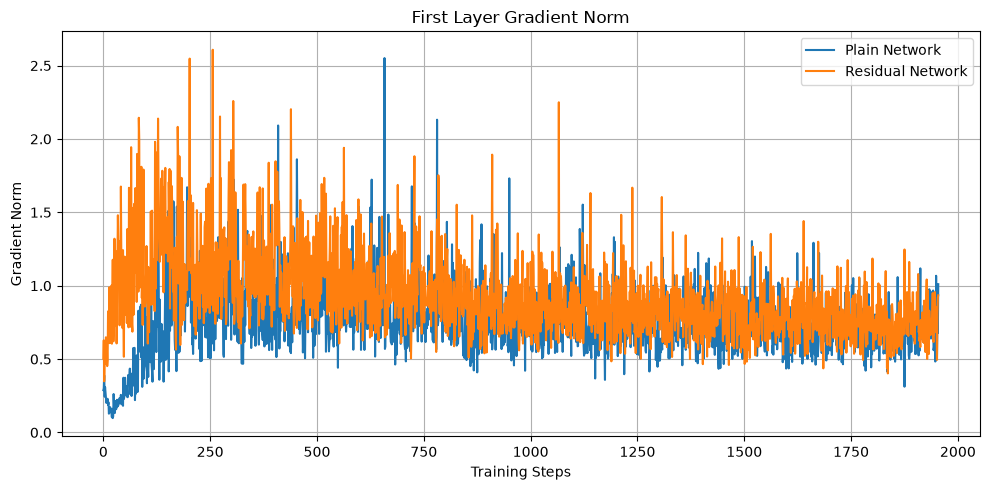

In [18]:
# Plot 
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(plain_grad_history, label="Plain Network")
ax.plot(res_grad_history, label="Residual Network")

ax.set(xlabel="Training Steps", ylabel="Gradient Norm", title="First Layer Gradient Norm")
ax.legend()
ax.grid(0.3)

plt.tight_layout()
plt.show()

**Explanation :-**
- In a plain network, the gradient must pass through multiple convolution layers.
- In a residual network, a shortcut path is available. Through this path, the gradient can reach earlier layers without having to cross the convolution layers.
- The residual network provides a direct gradient path through the identity shortcut. If the measured gradient norm is higher than the plain network, it supports the usual explanation, although gradient norm alone does not prove that training will always be better.

# **Part C — Build something that wins**
## **TASK 07 — A real ResNet on CIFAR-10**

In [26]:
# Create a Resnet Block
class BasicBlock(nn.Module):
    def __init__(
        self, in_channels, out_channels, stride=1,
        use_bn=True, final_relu=True, projection_everywhere=False
    ):
        super().__init__()
        self.use_bn = use_bn
        self.final_relu = final_relu

        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride,
                              padding=1, bias= not use_bn)
        self.bn1 = (nn.BatchNorm2d(out_channels)
                   if use_bn else nn.Identity())
        
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=not use_bn)
        self.bn2 = (nn.BatchNorm2d(out_channels)
                   if use_bn else nn.Identity())

        if (stride != 1
           or in_channels != out_channels
           or projection_everywhere):

            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias = False),
                nn.BatchNorm2d(out_channels)
            )

        else:
            self.shortcut = nn.Identity()


    def forward(self, x):
        identity = self.shortcut(x)
        out = self.conv1(x)
        out = self.bn1(out)

        out = F.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity

        if self.final_relu:
            out = F.relu(out)

        return out

In [27]:
# Create the ResNet Architecture
class SmallResNet(nn.Module):
    def __init__(
        self, blocks_per_stage=2, use_bn=True, final_relu=True,
        projection_everywhere=False, widths=(32, 64, 128)
    ):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]) if use_bn else nn.Identity(),
            nn.ReLU(inplace=True)
        )

        self.in_channels = widths[0]

        self.stage1 = self.make_stage(
            widths[0], blocks_per_stage, stride=1, use_bn=use_bn,
            final_relu=final_relu, projection_everywhere=projection_everywhere
        )
        self.stage2 = self.make_stage(
            widths[1], blocks_per_stage, stride=2, use_bn=use_bn,
            final_relu=final_relu, projection_everywhere=projection_everywhere
        )
        self.stage3 = self.make_stage(
            widths[2], blocks_per_stage, stride=2, use_bn=use_bn,
            final_relu=final_relu, projection_everywhere=projection_everywhere
        )

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[2], 10)


    def make_stage(
        self, out_channels, blocks, stride, use_bn, 
        final_relu, projection_everywhere
    ):
        layers = []

        for i in range(blocks):
            current_stride = stride if i == 0 else 1

            layers.append(BasicBlock(
                self.in_channels, out_channels,stride=current_stride, use_bn=use_bn,
                final_relu=final_relu, projection_everywhere=projection_everywhere
            ))

            self.in_channels = out_channels

        return nn.Sequential(*layers)



    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x)

        x = torch.flatten(x, 1)

        return self.fc(x)

In [28]:
# Train the ResNet
resnet = SmallResNet(blocks_per_stage=2)

print("ResNet Parameters:", count_parameters(resnet))

resnet, resnet_history, resnet_time = train_model(resnet, epochs=25, lr=0.01, seed=0)
resnet_accuracy = evaluate_model(resnet, test_loader)[0]

print("ResNet Test Accuracy:", resnet_accuracy)
print("ResNet Training Time:", resnet_time)

ResNet Parameters: 696618
Epoch 1/25 | Train Acc: 0.5091 | Test Acc: 0.5598
Epoch 2/25 | Train Acc: 0.6866 | Test Acc: 0.6378
Epoch 3/25 | Train Acc: 0.7549 | Test Acc: 0.7009
Epoch 4/25 | Train Acc: 0.7986 | Test Acc: 0.6934
Epoch 5/25 | Train Acc: 0.8293 | Test Acc: 0.7733
Epoch 6/25 | Train Acc: 0.8539 | Test Acc: 0.7684
Epoch 7/25 | Train Acc: 0.8721 | Test Acc: 0.6972
Epoch 8/25 | Train Acc: 0.8918 | Test Acc: 0.7626
Epoch 9/25 | Train Acc: 0.9098 | Test Acc: 0.7883
Epoch 10/25 | Train Acc: 0.9212 | Test Acc: 0.7445
Epoch 11/25 | Train Acc: 0.9384 | Test Acc: 0.7569
Epoch 12/25 | Train Acc: 0.9467 | Test Acc: 0.7522
Epoch 13/25 | Train Acc: 0.9558 | Test Acc: 0.8051
Epoch 14/25 | Train Acc: 0.9698 | Test Acc: 0.7803
Epoch 15/25 | Train Acc: 0.9719 | Test Acc: 0.7783
Epoch 16/25 | Train Acc: 0.9773 | Test Acc: 0.7557
Epoch 17/25 | Train Acc: 0.9832 | Test Acc: 0.7882
Epoch 18/25 | Train Acc: 0.9841 | Test Acc: 0.7612
Epoch 19/25 | Train Acc: 0.9888 | Test Acc: 0.7385
Epoch 20/25 | 

In [29]:
# Compare with Day51 CNN
print("Day 51 CNN Accuracy:", DAY51_CNN)
print("ResNet Accuracy:", resnet_accuracy)
print("ResNet Parameters:", count_parameters(resnet))
print("Accuracy Improvement:", (resnet_accuracy - DAY51_CNN) * 100, "percentage points")

Day 51 CNN Accuracy: 0.7304
ResNet Accuracy: 0.8059
ResNet Parameters: 696618
Accuracy Improvement: 7.54999999999999 percentage points


In [30]:
# Global average pooling vs flattening
# Assume feature map shap is:
# 128 channels, 8 x 8

channels = 128
height = 8
width = 8
classes = 10

# Flatten Approach
flatten_params = (channels * height * width * classes + classes)

# Global average pooling approach
gap_params = (channels * classes + classes)


print("Flatten classifier parameters:", flatten_params)
print("GAP classifier parameters:", gap_params)
print("Parameters saved:", flatten_params - gap_params)

Flatten classifier parameters: 81930
GAP classifier parameters: 1290
Parameters saved: 80640


**Explanation :-**
- In flattening, 128 × 8 × 8 = 8192 features are passed into the fully connected layer.
- In Global Average Pooling (GAP), the average of each channel is calculated, resulting in only 128 features.
- Therefore, GAP reduces the number of parameters and can also lower the risk of overfitting.

In [34]:
# Going deeper vs going wider
# Base ResNet
base_model = SmallResNet(blocks_per_stage=2, widths=(32, 64, 128))

# Deeper ResNet
deep_model = SmallResNet(blocks_per_stage=3, widths=(32, 64, 128))

# Wider ResNet
wide_model = SmallResNet(blocks_per_stage=2, widths=(48, 96, 192))



print("Base Parameters:", count_parameters(base_model))
print("Deep Parameters:", count_parameters(deep_model))
print("Wide Parameters:", count_parameters(wide_model))

Base Parameters: 696618
Deep Parameters: 1084586
Wide Parameters: 1564090


In [35]:
# Training and comparing both deeper and wider models:
deep_model, deep_history, deep_time = train_model(deep_model, epochs=10, seed=0)
wide_model, wide_history, wide_time = train_model(wide_model, epochs=10, seed=0)

print("Deep Accuracy:", evaluate_model(deep_model, test_loader)[0])
print("Wide Accuracy:", evaluate_model(wide_model, test_loader)[0])

Epoch 1/10 | Train Acc: 0.4986 | Test Acc: 0.5529
Epoch 2/10 | Train Acc: 0.6899 | Test Acc: 0.7055
Epoch 3/10 | Train Acc: 0.7703 | Test Acc: 0.7295
Epoch 4/10 | Train Acc: 0.8104 | Test Acc: 0.7562
Epoch 5/10 | Train Acc: 0.8410 | Test Acc: 0.7472
Epoch 6/10 | Train Acc: 0.8657 | Test Acc: 0.7872
Epoch 7/10 | Train Acc: 0.8858 | Test Acc: 0.7706
Epoch 8/10 | Train Acc: 0.9040 | Test Acc: 0.7382
Epoch 9/10 | Train Acc: 0.9217 | Test Acc: 0.7979
Epoch 10/10 | Train Acc: 0.9311 | Test Acc: 0.7864
Epoch 1/10 | Train Acc: 0.5144 | Test Acc: 0.6136
Epoch 2/10 | Train Acc: 0.7014 | Test Acc: 0.6116
Epoch 3/10 | Train Acc: 0.7770 | Test Acc: 0.7357
Epoch 4/10 | Train Acc: 0.8227 | Test Acc: 0.7688
Epoch 5/10 | Train Acc: 0.8528 | Test Acc: 0.7478
Epoch 6/10 | Train Acc: 0.8774 | Test Acc: 0.7614
Epoch 7/10 | Train Acc: 0.9015 | Test Acc: 0.7545
Epoch 8/10 | Train Acc: 0.9236 | Test Acc: 0.7465
Epoch 9/10 | Train Acc: 0.9405 | Test Acc: 0.7930
Epoch 10/10 | Train Acc: 0.9531 | Test Acc: 0.763

## **TASK 08 — Take it apart**

In [36]:
# Experiment 1 – Without Batch Normalization
resnet_no_bn = SmallResNet(blocks_per_stage=2, use_bn=False)
resnet_no_bn, no_bn_history, no_bn_time = train_model(resnet_no_bn, epochs=10, seed=0)
no_bn_accuracy = evaluate_model(resnet_no_bn, test_loader)[0]


print("Without BN Accuracy:", no_bn_accuracy)

Epoch 1/10 | Train Acc: 0.3433 | Test Acc: 0.2061
Epoch 2/10 | Train Acc: 0.4955 | Test Acc: 0.4429
Epoch 3/10 | Train Acc: 0.5852 | Test Acc: 0.5937
Epoch 4/10 | Train Acc: 0.6353 | Test Acc: 0.6289
Epoch 5/10 | Train Acc: 0.6697 | Test Acc: 0.5992
Epoch 6/10 | Train Acc: 0.6946 | Test Acc: 0.6339
Epoch 7/10 | Train Acc: 0.7147 | Test Acc: 0.6909
Epoch 8/10 | Train Acc: 0.7340 | Test Acc: 0.6966
Epoch 9/10 | Train Acc: 0.7506 | Test Acc: 0.7097
Epoch 10/10 | Train Acc: 0.7692 | Test Acc: 0.7250
Without BN Accuracy: 0.725


In [39]:
# Experiment 2 – Move ReLU before addition
class ReluBeforeAdditionBlock(BasicBlock):
    def forward(self, x):
        identify = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = F.relu(out)
        out = out + identify

        return out



class ReluBeforeAdditionResNet(SmallResNet):
    def make_stage(
        self, out_channels, blocks, stride, use_bn,
        final_relu, projection_everywhere
    ):
        layers = []

        for i in range(blocks):
            current_stride = stride if i == 0 else 1

            layers.append(ReluBeforeAdditionBlock(
                self.in_channels, out_channels, stride=current_stride,
                use_bn=use_bn, projection_everywhere=projection_everywhere
            ))

            self.in_channels = out_channels
        return nn.Sequential(*layers)



resnet_relu_before = ReluBeforeAdditionResNet(blocks_per_stage=2)
resnet_relu_before, relu_history, relu_time = train_model(
    resnet_relu_before, epochs=10, seed=0
)

relu_accuracy = evaluate_model(resnet_relu_before, test_loader)[0]

print("ReLU before addition accuracy:", relu_accuracy)

Epoch 1/10 | Train Acc: 0.4947 | Test Acc: 0.5256
Epoch 2/10 | Train Acc: 0.6645 | Test Acc: 0.5895
Epoch 3/10 | Train Acc: 0.7339 | Test Acc: 0.6689
Epoch 4/10 | Train Acc: 0.7789 | Test Acc: 0.6737
Epoch 5/10 | Train Acc: 0.8116 | Test Acc: 0.7197
Epoch 6/10 | Train Acc: 0.8371 | Test Acc: 0.7550
Epoch 7/10 | Train Acc: 0.8567 | Test Acc: 0.7483
Epoch 8/10 | Train Acc: 0.8728 | Test Acc: 0.7099
Epoch 9/10 | Train Acc: 0.8919 | Test Acc: 0.7596
Epoch 10/10 | Train Acc: 0.9058 | Test Acc: 0.7626
ReLU before addition accuracy: 0.7626


In [40]:
# Experiment 3 – Projection Shortcut Everywhere
resnet_projection = SmallResNet(blocks_per_stage=2, projection_everywhere=True)

resnet_projection, projection_history, projection_time = train_model(
    resnet_projection, epochs=10, seed=0
)

projection_accuracy = evaluate_model(resnet_projection, test_loader)[0]

print("Projection Everywhere Accuracy:", projection_accuracy)
print("Projection Parameters:", count_parameters(resnet_projection))

Epoch 1/10 | Train Acc: 0.4990 | Test Acc: 0.5561
Epoch 2/10 | Train Acc: 0.6775 | Test Acc: 0.6793
Epoch 3/10 | Train Acc: 0.7477 | Test Acc: 0.6828
Epoch 4/10 | Train Acc: 0.7928 | Test Acc: 0.6647
Epoch 5/10 | Train Acc: 0.8260 | Test Acc: 0.7085
Epoch 6/10 | Train Acc: 0.8493 | Test Acc: 0.7600
Epoch 7/10 | Train Acc: 0.8675 | Test Acc: 0.7567
Epoch 8/10 | Train Acc: 0.8863 | Test Acc: 0.7726
Epoch 9/10 | Train Acc: 0.9054 | Test Acc: 0.8181
Epoch 10/10 | Train Acc: 0.9176 | Test Acc: 0.7175
Projection Everywhere Accuracy: 0.7175
Projection Parameters: 719658


In [41]:
# Final Ablation Table
baseline_accuracy = resnet_accuracy
ablation_results = [
    {
        "Model": "Original ResNet",
        "Accuracy": baseline_accuracy,
        "Parameters": count_parameters(resnet)
    },
    {
        "Model": "Without BatchNorm",
        "Accuracy": no_bn_accuracy,
        "Parameters": count_parameters(resnet_no_bn)
    },
    {
        "Model": "ReLU Before Addition",
        "Accuracy": relu_accuracy,
        "Parameters": count_parameters(resnet_relu_before)
    },
    {
        "Model": "Projection Everywhere",
        "Accuracy": projection_accuracy,
        "Parameters": count_parameters(resnet_projection)
    }
]


ablation_table = pd.DataFrame(ablation_results)

ablation_table["Accuracy Change"] = (ablation_table["Accuracy"] - baseline_accuracy)


print(ablation_table)

                   Model  Accuracy  Parameters  Accuracy Change
0        Original ResNet    0.8059      696618           0.0000
1      Without BatchNorm    0.7250      695658          -0.0809
2   ReLU Before Addition    0.7626      696618          -0.0433
3  Projection Everywhere    0.7175      719658          -0.0884


**Explanation :-**
- Original - Normal ResNet
- Without BN - Batch Normalization Remove
- ReLU Before Addition - Change the position of activation
- Projection Everywhere - 1x1 Convolution at each shortcut

## **TASK 09 — Read the errors**

In [47]:
class CNN(nn.Module):

    def __init__(self, pooling="max", use_pool=True, first_kernel=3,
                batch_norm=False, extra_block=False):

        super().__init__()

        Pool = nn.MaxPool2d if pooling == "max" else nn.AvgPool2d
        layers = []

        def block(in_channels, out_channels, kernel=3):
            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=kernel, padding=kernel // 2))

            if batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.append(nn.ReLU())

            if use_pool:
                layers.append(Pool(2))

        block(3, 64, first_kernel)
        block(64, 128)

        if extra_block:
            block(128, 256)


        self.features = nn.Sequential(*layers)

        with torch.no_grad():
            dummy = torch.zeros(1, 3, 32, 32)
            output = self.features(dummy)
            flatten_size = output.flatten(1).shape[1]

        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(flatten_size, 256),
                                       nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 10))


    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)

        return x

cnn_model = CNN().to(device)

In [48]:
# Predictions 
def get_predictions(model, loader):
    model = model.to(device)

    model.eval()

    all_predictions = []
    all_labels = []
    all_images = []

    with torch.no_grad():
        for images, labels in loader:
            image_device = images.to(device)
            outputs = model(image_device)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())
            
            all_images.append(images)


    all_images = torch.cat(all_images)

    return (np.array(all_predictions),
           np.array(all_labels), all_images)




# Best RestNet Predictions
resnet_predictions, true_labels, test_images = get_predictions(resnet, test_loader)

# Day 51 CNN predictions
day51_model = cnn_model

day51_predictions, _, _ = get_predictions(day51_model, test_loader)


print("ResNet Predictions:", len(resnet_predictions))
print("Day 51 Predictions:", len(day51_predictions))

ResNet Predictions: 10000
Day 51 Predictions: 10000


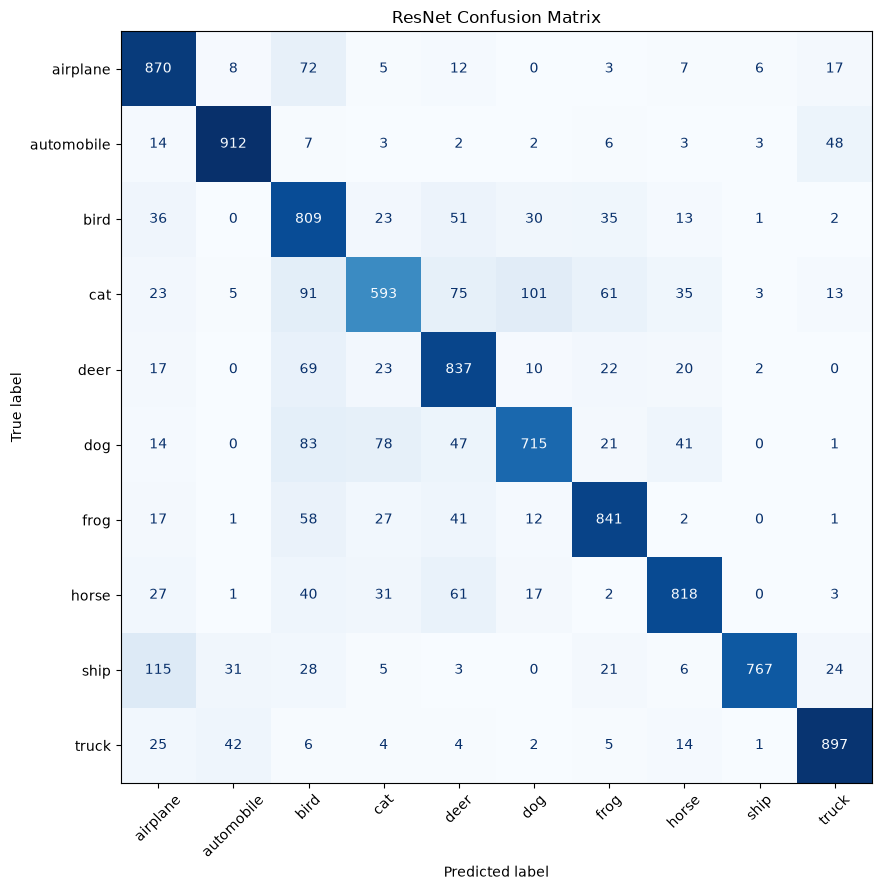

In [49]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(true_labels, resnet_predictions)

fig, ax = plt.subplots(figsize=(11, 9))

display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

display.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)

ax.set_title("ResNet Confusion Matrix")

plt.tight_layout()
plt.show()

In [51]:
# Find Three Worst Confused Pairs
confusion_pairs = []

for i in range(10):
    for j in range(10):
        if i != j:

            confusion_pairs.append({
                "Actual": class_names[i],
                "Predicted": class_names[j],
                "Count": cm[i, j]
            })


confusion_pairs = sorted(confusion_pairs,
                        key=lambda x: x["Count"], reverse=True)


print("Three Worst confused pairs:")

for pair in confusion_pairs[:3]:
    print(pair)

Three Worst confused pairs:
{'Actual': 'ship', 'Predicted': 'airplane', 'Count': np.int64(115)}
{'Actual': 'cat', 'Predicted': 'dog', 'Count': np.int64(101)}
{'Actual': 'cat', 'Predicted': 'bird', 'Count': np.int64(91)}


In [53]:
# Compare Day51 and Day52
day51_cm = confusion_matrix(true_labels, day51_predictions)

print("Day 51 top confusion pairs:")

day51_pairs = []

for i in range(10):
    for j in range(10):
        if i != j:
            day51_pairs.append({
                "Actual": class_names[i],
                "Predicted": class_names[j],
                "Count": day51_cm[i, j]
            })



day51_pairs = sorted(day51_pairs, 
                    key=lambda x: x["Count"], reverse=True)


for pair in day51_pairs[:3]:
    print(pair)

Day 51 top confusion pairs:
{'Actual': 'deer', 'Predicted': 'truck', 'Count': np.int64(575)}
{'Actual': 'frog', 'Predicted': 'truck', 'Count': np.int64(558)}
{'Actual': 'horse', 'Predicted': 'truck', 'Count': np.int64(549)}


In [54]:
# Display regression images
regression_indices = np.where(
    (day51_predictions == true_labels)
    &
    (resnet_predictions != true_labels)
)[0]

print("Regression images:", len(regression_indices))

Regression images: 118


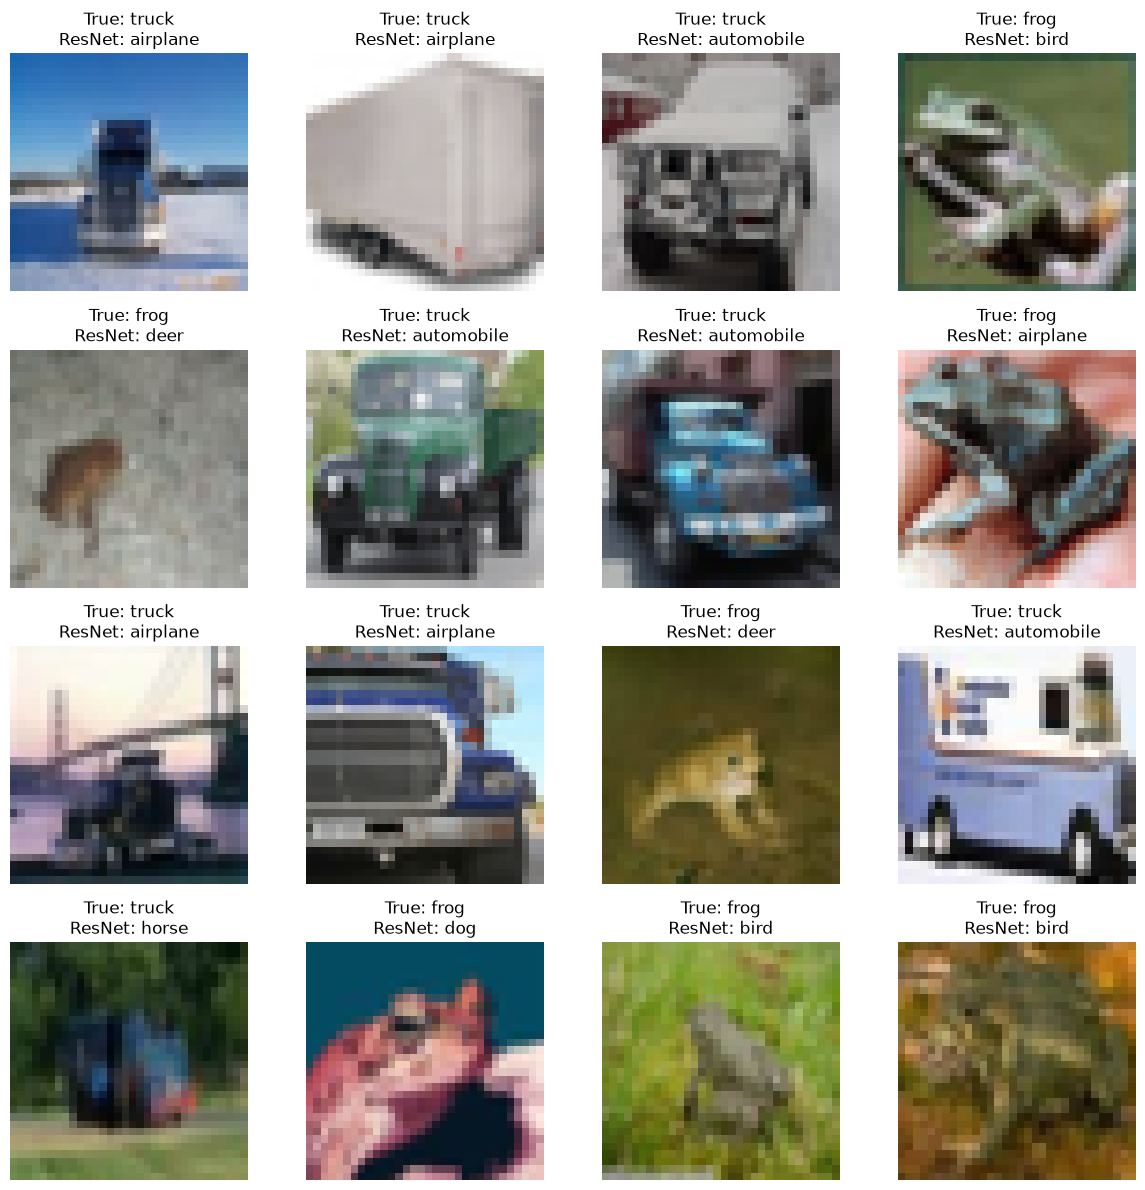

In [55]:
# Display images
number_of_images = min(16, len(regression_indices))

fig, ax = plt.subplots(4, 4, figsize=(12, 12))

ax = ax.flatten()

for i in range(16):
    ax[i].axis("off")

    if i < number_of_images:
        idx = regression_indices[i]
        image = test_images[idx].permute(1, 2, 0).numpy()
        ax[i].imshow(image)
        ax[i].set_title(f"True: {class_names[true_labels[idx]]}\n"
                       f"ResNet: {class_names[resnet_predictions[idx]]}")


plt.tight_layout()
plt.show()